# Multi-Agent Financial Analysis System
**AAI-520 Final Team Project**  
**Tim Hays · Roopleen Kaur · Ashley Marx**  
[GitHub repository](https://github.com/tim17hays/NLP_AAI520) · [Final project branch](https://github.com/tim17hays/NLP_AAI520/tree/codex/final-team-integration)

This final report documents planning, specialist tool use, self-reflection and persistent memory, together with news chaining, routing and evaluator–optimizer workflows. It includes actual AAPL provider/model evidence, real Qwen baseline failures, an evidence-tool correction strategy, and an observed two-run memory-policy demonstration. Model acceptance and evidence verification are reported as separate outcomes.

**How to read the results:** The original free-form Qwen baseline failed acceptance in both runs. The completed hybrid demonstration uses Qwen to critique and score, Python to calculate and cite a bounded evidence brief, and a saved process lesson to activate the safer policy before the second draft. Model judgments, tool-generated text, scripted tests and recorded experiments are labeled separately. The results establish a software-policy benefit on fixed fictional evidence, not general financial accuracy, model fine-tuning or an investment recommendation.

**Reproducibility:** Run all reproduces this report and validates the supplied experiment records without downloading model weights. The model-execution commands and exact recorded runtime details appear below. Fresh provider/model experiments are optional reproductions, not prerequisites for reading this completed submission.


## 1. Design, ownership and rubric evidence
| Requirement | Implementation | Visible evidence |
|---|---|---|
| Plans research | `ResearchPlanner.plan()` | Section 4: selected specialists, ordered steps and lesson-review step |
| Uses tools dynamically | Research-question routing selects tools | Section 4: market/earnings/news/fallback routes; AAPL tool and error trace |
| Self-reflects | Real Qwen critique plus citation/content guards | Sections 7–8: original judgments, failures, re-evaluation and acceptance |
| Learns across runs | Saved process lesson activates a fixed safer policy | Section 8: disk record, lesson identity, next plan and draft; same-input ablation |
| Prompt chaining | Ingest → preprocess → classify → extract → summarize | Section 3: trace, deduplication, actual FinBERT inference and source alignment |
| Routing | Market, earnings, news and company specialists | Section 4: different questions select different specialist tools |
| Evaluator–optimizer | Critique → evidence-tool revision → re-evaluation | Section 8: failed original, repaired brief and subsequent real model judgment |
| Code and communication | Reusable modules, tests, GitHub, comments, diagrams and disclosure | Sections 1–10 and references |

Tim owns retrieval/news and integration; Roopleen owns planning/routing and initial draft generation; Ashley owns evaluation, revision and persistent memory. The final integration adds an explicitly labeled evidence-tool optimizer and keeps their component implementations and historical experiment records traceable in Git.

The architecture combines LLM judgment with deterministic routing and arithmetic. Routing is a documented keyword heuristic. Memory changes an auditable drafting policy; it does not update model weights. The bounded numeric brief is applicable only when its required compatible inputs, units and periods are supplied.


In [1]:
from IPython.display import HTML, Markdown, display
stages = ["Plan / route", "Retrieve / news chain", "Draft", "Evaluate / revise", "Save lesson → next plan"]
boxes = ''.join(f'<div style="flex:1;padding:14px 8px;border:1px solid #8caac5;border-radius:8px;background:#edf4fb;text-align:center">{s}</div>' for s in stages)
display(HTML('<div style="display:flex;gap:8px;flex-wrap:wrap;font:14px system-ui">'+boxes+'</div>'))

## 2. Reproducible runtime and repository
The original generation/review model is `Qwen/Qwen2.5-1.5B-Instruct`; the resource-bounded local reviewer is `Qwen/Qwen2.5-0.5B-Instruct`; news sentiment uses `ProsusAI/finbert`. Both run through Hugging Face Transformers without a paid LLM API key. Optional Finnhub/Alpha Vantage credentials remain outside the repository.

The report displays the actual Colab baseline and local model-experiment metadata. Its default execution validates and presents those recorded results; this does not claim a new model call on every report execution. The source and experiment artifacts are included in the final branch. The loader supports CUDA, Apple MPS and CPU; CPU execution is slower.

To repeat the experiments with model weights installed, run `python -m scripts.run_grounded_demo --output outputs/NEW_EXPERIMENT_DIRECTORY` and `python -m scripts.run_finbert_demo --model-path PATH_TO_FINBERT --output outputs/finbert_demo.json`. A new directory prevents memory contamination. `AAI520_DEVICE` selects a device; `AAI520_MODEL_PATH` can identify a local cached Qwen snapshot.


In [2]:
import importlib.util, json, os, subprocess, sys
from pathlib import Path
from datetime import datetime, timezone
IN_COLAB = bool(importlib.util.find_spec("google")) and bool(importlib.util.find_spec("google.colab"))
REPO_URL = "https://github.com/tim17hays/NLP_AAI520.git"
TEAM_BRANCH = "codex/final-team-integration"
RUN_LIVE_MODELS = IN_COLAB and os.getenv("AAI520_FRESH_BASELINE") == "1"
if IN_COLAB:
    REPO = Path("/content/NLP_AAI520-final-review")
    if not REPO.exists():
        subprocess.run(["git", "clone", "--branch", TEAM_BRANCH, REPO_URL, str(REPO)], check=True)
    else:
        changes = subprocess.check_output(["git", "-C", str(REPO), "status", "--porcelain"], text=True)
        if changes.strip():
            raise RuntimeError("Existing Colab clone has edits. Preserve them before reusing this folder.")
        subprocess.run(["git", "-C", str(REPO), "fetch", "origin", TEAM_BRANCH], check=True)
        subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", "FETCH_HEAD"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO / "requirements.txt")], check=True)
else:
    REPO = Path.cwd()
    if REPO.name == "notebooks": REPO = REPO.parent
if not (REPO / "src/evaluation_memory.py").is_file():
    raise RuntimeError("Run from the combined project checkout.")
os.chdir(REPO)
if str(REPO) not in sys.path: sys.path.insert(0, str(REPO))
TEAM_COMMIT = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip()
print("Code commit:", TEAM_COMMIT)
print("Python:", sys.version.split()[0])
print("Execution mode:", "fresh Colab model calls" if RUN_LIVE_MODELS else "final report: verified recorded experiments and executable checks")
if RUN_LIVE_MODELS:
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("Select a Colab CUDA GPU runtime, then restart Run all.")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Torch:", torch.__version__)


Code commit: 1f9c6c42a70bb940c35f5588a68b59613485a1ff
Python: 3.13.15
Execution mode: final report: verified recorded experiments and executable checks


In [3]:
import inspect
from dataclasses import asdict, is_dataclass
from src.data_tools import StockResearchTools
from src.news_pipeline import NewsPipeline
from src.planning import ResearchPlanner
from src.llm import MODEL_NAME, generate_draft
from src import evaluation_memory as evaluation
# Reuse loaded model weights but refresh the small response-handling modules.
import importlib
from src import model_transport
importlib.reload(model_transport)
importlib.reload(evaluation)
from src.evaluation_memory import (
    qwen_call_model, run_research_with_memory, MODEL_CALL_LOG, MAX_REVISIONS,
    check_citations, derived_calculations, read_lessons, utc_now, json_copy, require_text,
)
TEAM_PLANNER = ResearchPlanner()
CALL_MODEL = qwen_call_model
from uuid import uuid4
OUTPUT_DIR = REPO / "outputs" / ("final_submission_" + uuid4().hex)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Draft model:", MODEL_NAME)
assert getattr(qwen_call_model, "schema_attempt_limit", None) == 2, "Refresh the repository/imports before running models."
print("Structured response attempts per call:", qwen_call_model.schema_attempt_limit)
print("Planner signature:", inspect.signature(ResearchPlanner.execute))
print("Revision limit:", MAX_REVISIONS)

Draft model: Qwen/Qwen2.5-1.5B-Instruct
Structured response attempts per call: 2
Planner signature: (self, ticker: 'str', research_question: 'str', lessons: 'list | None' = None) -> 'dict[str, Any]'
Revision limit: 2


## 3. News prompt chain and source validation — Tim
The production chain ingests news, normalizes text and URLs, deduplicates records, classifies retained text with FinBERT, extracts source sentences and produces a source-preserving summary. Every stage leaves a visible trace.

The first checks use a deterministic injected classifier to isolate provenance and error behavior. The subsequent experiment uses actual FinBERT inference on explicitly fictional classroom news; its input is duplicated to test preprocessing. Neither classification confidence nor a source quotation establishes the truth of an article or predicts a stock return.

Yahoo news requests have a 20-second per-request timeout and a 15-minute successful-result cache. The fallback order is Yahoo → Finnhub → Alpha Vantage. Historical-price requests use a 15-second timeout. These are per-request bounds, not an overall workflow deadline.


In [4]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src.news_pipeline import NewsPipeline
from src.data_tools import StockResearchTools
class FixtureClassifier:
    def classify(self, text):
        return "neutral", 1.0
raw = [
    {"title": "Apple synthetic financial report", "summary": "Revenue was 100 in the synthetic example.",
     "publisher": "Synthetic fixture", "link": "https://example.com/aapl-fixture?tracking=1"},
    {"title": "Duplicate fixture", "summary": "This duplicate should be removed.",
     "publisher": "Synthetic fixture", "link": "https://example.com/aapl-fixture"},
]
result = NewsPipeline(classifier=FixtureClassifier()).process("AAPL", raw)
print(json.dumps(result["trace"], indent=2))

{
  "ingest": {
    "input_count": 2
  },
  "preprocess": {
    "retained_count": 1,
    "records": [
      {
        "text": "Apple synthetic financial report. Revenue was 100 in the synthetic example.",
        "url": "https://example.com/aapl-fixture"
      }
    ]
  },
  "classify_finbert": [
    {
      "url": "https://example.com/aapl-fixture",
      "label": "neutral",
      "score": 1.0
    }
  ],
  "extract": [
    {
      "url": "https://example.com/aapl-fixture",
      "facts": [
        "Revenue was 100 in the synthetic example."
      ]
    }
  ],
  "summarize": "Processed 1 source-attributed news items (1 neutral). Representative headlines: Apple synthetic financial report."
}


In [5]:
assert len(result["items"]) == 1
item = result["items"][0]
assert item["source"]["url"] == "https://example.com/aapl-fixture"
assert all(fact in result["trace"]["preprocess"]["records"][0]["text"] for fact in item["extracted_facts"])
assert item["title"] in result["summary"]
print("PASS: deduplication, extracted-source alignment, headline-summary alignment")
print(result["summary"])

PASS: deduplication, extracted-source alignment, headline-summary alignment
Processed 1 source-attributed news items (1 neutral). Representative headlines: Apple synthetic financial report.


In [6]:
class FailedTicker:
    def get_news(self, **kwargs):
        raise TimeoutError("synthetic provider timeout")
empty = NewsPipeline(ticker_factory=lambda _: FailedTicker(), classifier=FixtureClassifier(), fallback_news_sources=[]).process("AAPL")
assert empty["items"] == [] and empty["errors"]
print(json.dumps({"summary": empty["summary"], "errors": empty["errors"]}, indent=2))
class FailedClassifier:
    def classify(self, text):
        raise RuntimeError("synthetic model unavailable")
failed = NewsPipeline(classifier=FailedClassifier()).process("AAPL", raw[:1])
assert failed["items"][0]["sentiment"] == "unavailable"
print(json.dumps({"sentiment": failed["items"][0]["sentiment"], "errors": failed["errors"]}, indent=2))

{
  "summary": "No deduplicated news evidence was available for this run.",
  "errors": [
    "Yahoo Finance news failed: synthetic provider timeout"
  ]
}
{
  "sentiment": "unavailable",
  "errors": [
    "FinBERT classification failed for 'Apple synthetic financial report': synthetic model unavailable"
  ]
}


The checks link extracted sentences to the retained source text, confirm deduplication, and preserve missing-data/classifier failures. They verify provenance and error behavior, not truth of the article or investment value. Financial snapshots do not establish a reporting period unless the provider explicitly supplies one.

### Actual FinBERT chaining experiment
The artifact below was produced by running the real `ProsusAI/finbert` model through the production `NewsPipeline` on duplicated fictional source text. It shows the complete five-stage trace, removes the duplicate and retains the source alignment. This is an execution example, not a measured sentiment-accuracy benchmark.


In [7]:
news_model_report = json.loads((REPO / "data/examples/final_finbert_demonstration.json").read_text())
assert news_model_report["execution_mode"] == "fresh_local_finbert"
news_model_result = news_model_report["result"]
assert news_model_result["workflow"] == ["ingest", "preprocess", "classify_finbert", "extract", "summarize"]
assert not news_model_result["errors"]
assert news_model_result["trace"]["ingest"]["input_count"] == 2
assert news_model_result["trace"]["preprocess"]["retained_count"] == 1
print("Actual model runtime:", json.dumps({key: value for key, value in news_model_report.items() if key not in ("result", "raw_news")}, indent=2))
print("Input:", json.dumps(news_model_report["raw_news"], indent=2))
print("Five-stage output:", json.dumps(news_model_result["trace"], indent=2))
print("Source-attributed summary:", news_model_result["summary"])
print("PASS: actual FinBERT inference, deduplication and all five workflow stages.")


Actual model runtime: {
  "execution_mode": "fresh_local_finbert",
  "input_mode": "frozen fictional classroom news, duplicated to test preprocessing",
  "model": "ProsusAI/finbert",
  "model_snapshot": "4556d13015211d73dccd3fdd39d39232506f3e43",
  "torch": "2.6.0",
  "transformers": "4.51.3",
  "finished_at": "2026-10-19T23:42:06.142201+00:00"
}
Input: [
  {
    "title": "Fictional DEMO reports supplier delays",
    "summary": "Supplier delays could increase near-term costs. The impact is not quantified. No stock-price target is supplied.",
    "publisher": "Fictional classroom source",
    "link": "https://example.com/fictional-demo/news",
    "published_at": "2026-09-25T00:00:00+00:00"
  },
  {
    "title": "Fictional DEMO reports supplier delays",
    "summary": "Supplier delays could increase near-term costs. The impact is not quantified. No stock-price target is supplied.",
    "publisher": "Fictional classroom source",
    "link": "https://example.com/fictional-demo/news",
    "

## 4. Planning, specialist routing and draft generation — Roopleen
The planner selects specialists using research-question keywords, calls the corresponding tools, and returns evidence, a structured plan, tool/error trace, retrieved lessons and a draft. Unsupported or unclear wording falls back to a company-profile route; this is a documented heuristic rather than evidence of semantic understanding.

In [8]:
questions = {
    "market": "Summarize stock price performance.",
    "earnings": "Summarize earnings and revenue.",
    "news": "Summarize recent news sentiment.",
    "fallback": "Explain this unrelated request.",
}
for name, question in questions.items():
    plan = TEAM_PLANNER.plan("AAPL", question)
    print(name, "→", plan.specialists)
lesson_plan = TEAM_PLANNER.plan("AAPL", "market and financial news", lessons=["Do not infer reporting periods."])
print("Lesson-aware first step:", lesson_plan.steps[0])
print("\nPlanner execution code:\n", inspect.getsource(ResearchPlanner.execute))

market → ['market']
earnings → ['earnings']
news → ['news']
fallback → ['company']
Lesson-aware first step: Review retrieved lessons before collecting and drafting evidence: ['Do not infer reporting periods.']

Planner execution code:
     def execute(
        self, ticker: str, research_question: str, lessons: list | None = None
    ) -> dict[str, Any]:
        """Execute the specialists selected for the research question."""
        symbol = self.normalize_ticker(ticker)
        specialists = self.route(research_question)

        if not specialists:
            specialists = ["company"]

        plan = self.plan(symbol, research_question, lessons=lessons)
        evidence: dict[str, Any] = {}

        for specialist in specialists:
            if specialist == "market":
                result = self._research_tools.market_snapshot(symbol)
                evidence["market"] = result.to_dict()

            elif specialist == "earnings":
                result = self._research_tools.fi

### AAPL provider evidence and Qwen draft
This section preserves the AAPL provider/model result from the completed Colab execution associated with commit `34dbce9`. Its source URLs, access times, missing values and errors remain visible. It demonstrates real provider integration separately from the fixed fictional benchmark used to test correction and memory.


In [9]:
if RUN_LIVE_MODELS:
    AAPL_RESULT = TEAM_PLANNER.execute(
        "AAPL", "Summarize Apple's market performance, financial metrics, and recent news with source URLs and limitations.",
        lessons=[],
    )
    AAPL_MODE = "fresh provider/model execution"
else:
    AAPL_RESULT = json.loads((REPO / "data/examples/final_aapl_colab_result.json").read_text())
    AAPL_MODE = "Recorded fresh Colab provider/model evidence, commit 34dbce9"
print("AAPL mode:", AAPL_MODE)
print("Plan:", json.dumps(AAPL_RESULT["plan"], indent=2))
print("Tool/error trace:", json.dumps(AAPL_RESULT["tool_trace"], indent=2))
for name in ("market", "earnings"):
    print(name, json.dumps(AAPL_RESULT["evidence"].get(name, {}), indent=2))
news = AAPL_RESULT["evidence"].get("news", {})
print("News sources:", json.dumps([{"title": i.get("title"), "url": i.get("url"), "sentiment": i.get("sentiment")} for i in news.get("items", [])], indent=2))
print("DRAFT (model output; inspect against evidence):\n", AAPL_RESULT["draft_analysis"])
(OUTPUT_DIR / "aapl_result.json").write_text(json.dumps(AAPL_RESULT, indent=2))


AAPL mode: Recorded fresh Colab provider/model evidence, commit 34dbce9
Plan: {
  "ticker": "AAPL",
  "research_question": "Summarize Apple's market performance, financial metrics, and recent news with source URLs and limitations.",
  "specialists": [
    "market",
    "earnings",
    "news"
  ],
  "steps": [
    "Retrieve evidence from the market specialist.",
    "Retrieve evidence from the earnings specialist.",
    "Retrieve evidence from the news specialist.",
    "Combine the retrieved evidence into a draft analysis.",
    "Send the draft analysis and supporting evidence for evaluation."
  ],
  "retrieved_lessons": []
}
Tool/error trace: [
  {
    "specialist": "market",
    "tool": "market_snapshot",
    "errors": []
  },
  {
    "specialist": "earnings",
    "tool": "financial_snapshot",
    "errors": []
  },
  {
    "specialist": "news",
    "tool": "news_pipeline",
    "errors": []
  }
]
market {
  "tool": "market_snapshot",
  "ticker": "AAPL",
  "data": {
    "period": "1mo"

18420

Source-attributed retrieval does not guarantee a grounded generated narrative. The AAPL draft is retained as model output and must be interpreted against the displayed source records. The controlled correction experiment below evaluates specific known errors without pretending that a model score independently verifies real-world financial claims.


## 5. Evaluation, revision and persistent memory — Ashley
The evaluator scores evidence support, completeness, consistency, uncertainty and clarity from 0–2. Passing requires at least 8/10, no zero criterion, full evidence support and consistency, and no critical issues. Citation checks reject missing/unknown references. Narrow benchmark checks validate selected computed facts; they are not general factual verification.

The loop stops on acceptance, at two revisions, or when a revised draft is unchanged. It never converts a failure into a pass for presentation. Process lessons can be saved after a verified failure without endorsing the failed financial claims. Duplicate lessons reuse an existing record; `saved_lesson` being non-null does not mean a second unique lesson was created.

The shared transport permits one additional model attempt when JSON/schema validation fails. The retry receives the original evidence plus the exact validation error and raw invalid response. Both attempts remain logged. Missing criteria are never supplied by Python, and two invalid attempts still stop the run. This format retry does not change scoring or count as an analysis revision.


In [10]:
print("Evaluation and guard checks:\n", inspect.getsource(evaluation.evaluate_analysis))
print("Bounded revision:\n", inspect.getsource(evaluation.run_evaluation_revision))
print("Process-lesson policy:\n", inspect.getsource(evaluation.select_process_lesson))

Evaluation and guard checks:
 def evaluate_analysis(context, draft, call_model, lessons=None):
    payload = build_evaluation_payload(
        context,
        draft,
        lessons,
    )

    check = check_citations(
        payload["draft_analysis"],
        payload["evidence"],
    )
    payload["deterministic_citation_check"] = check

    content_check = check_benchmark_content(context, draft)
    payload["deterministic_content_check"] = content_check
    payload["derived_calculations"] = derived_calculations(payload["evidence"])

    raw = validate_evaluation(
        call_json_model(
            call_model,
            EVALUATOR_INSTRUCTIONS,
            payload,
        )
    )

    evaluation = json_copy(raw)
    lesson_origin = "model" if raw["lesson"].strip() else "none"

    if check["issues"]:
        cap = 1 if check["recognized_references"] else 0

        evaluation["scores"]["evidence_support"] = min(
            evaluation["scores"]["evidence_support"],
            c

### Controlled benchmark and offline checks
The DEMO company, figures, dates, news and `example.com` URLs are fictional classroom evidence. Expected calculations are 20% revenue growth, 10% operating margin and 10% closing-price change. No prior operating-income value, guaranteed return or price target is supplied.

The acceptance checks below use scripted fixtures; this verifies code/data flow and stopping rules, not real model performance. The following section separately uses real Qwen responses.

In [11]:
benchmark = json.loads((REPO / "data/examples/controlled_demo_inputs.json").read_text())
DEMO_QUESTION = benchmark["DEMO_QUESTION"]
SAMPLE_CONTEXT = benchmark["SAMPLE_CONTEXT"]
REFERENCE_ANALYSIS = benchmark["REFERENCE_ANALYSIS"]
print("Fictional evidence:", json.dumps(SAMPLE_CONTEXT["evidence"], indent=2))
print("Derived benchmark calculations:", derived_calculations(SAMPLE_CONTEXT["evidence"]))
checks = subprocess.run([sys.executable, "-m", "pytest", "-q"], text=True, capture_output=True,
                        env={**os.environ, "PYTEST_DISABLE_PLUGIN_AUTOLOAD": "1", "AAI520_LIVE_TESTS": "0"})
print(checks.stdout)
if checks.returncode:
    print(checks.stderr)
    raise RuntimeError("Offline checks failed; resolve before submission.")

Fictional evidence: {
  "market": {
    "tool": "market_snapshot",
    "ticker": "DEMO",
    "data": {
      "currency": "USD",
      "first_close": 40,
      "latest_close": 44,
      "start_date": "2026-08-31",
      "as_of": "2026-09-30",
      "dividends_and_corporate_actions": "not supplied"
    },
    "sources": [
      {
        "name": "Fictional closing-price record",
        "url": "https://example.com/fictional-demo/prices",
        "accessed_at": "2026-10-01T00:00:00+00:00"
      }
    ],
    "errors": []
  },
  "earnings": {
    "tool": "financial_snapshot",
    "ticker": "DEMO",
    "data": {
      "currency": "USD",
      "unit": "million",
      "current_period": "Q2 2026",
      "previous_period": "Q2 2025",
      "current_revenue": 120,
      "previous_revenue": 100,
      "operating_income": 12,
      "management_forecast": null
    },
    "sources": [
      {
        "name": "Fictional classroom financial statement",
        "url": "https://example.com/fictional-dem

## 6. Original real-model baseline
The original Colab experiment used fixed fictional DEMO evidence. Run 1 began with an uncited benchmark draft; Run 2 used Qwen generation after receiving a saved lesson. Both evaluation/revision histories are retained, including failed outcomes.

The different starting draft origins prevent a causal comparison of memory from these two baseline scores. Section 8 therefore holds the raw candidate and evidence fixed when testing the new memory-controlled drafting policy. The baseline remains a record of free-form model behavior, not evidence of successful correction.


In [12]:
import copy
import json

from dataclasses import asdict, is_dataclass
from pathlib import Path
from uuid import uuid4
from zipfile import ZIP_DEFLATED, ZipFile

required_names = [
    "TEAM_PLANNER",
    "CALL_MODEL",
    "qwen_call_model",
    "MODEL_NAME",
    "TEAM_COMMIT",
    "REFERENCE_ANALYSIS",
    "SAMPLE_CONTEXT",
    "DEMO_QUESTION",
    "MODEL_CALL_LOG",
    "OUTPUT_DIR",
    "MAX_REVISIONS",
    "run_research_with_memory",
    "check_citations",
    "json_copy",
    "require_text",
    "utc_now",
]

missing_names = [
    name for name in required_names if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "Run the earlier notebook cells through Section 11 first. "
        "Missing: " + ", ".join(missing_names)
    )

if CALL_MODEL is not qwen_call_model:
    raise RuntimeError(
        "Section 11 must connect CALL_MODEL to the real Qwen model."
    )

from src.llm import generate_draft


def remove_reference_citations(text):
    """Prepare a deliberately uncited, human-written test draft."""
    for citation in (
        "[evidence.earnings; evidence.news.items[0]]",
        "[evidence.news.items[0]]",
        "[evidence.earnings]",
        "[evidence.market]",
    ):
        text = text.replace(citation, "")

    return text.strip()


CONTROLLED_START_DRAFT = remove_reference_citations(
    REFERENCE_ANALYSIS
)

assert not check_citations(
    CONTROLLED_START_DRAFT,
    SAMPLE_CONTEXT["evidence"],
)["passed"]


class FrozenEvidencePlanner:
    """Use team planning and drafting with frozen fictional evidence."""

    def __init__(
        self,
        team_planner,
        draft_generator,
        initial_draft=None,
    ):
        self.team_planner = team_planner
        self.draft_generator = draft_generator
        self.initial_draft = initial_draft
        self.calls = []

    def execute(self, ticker, research_question, lessons=None):
        lessons = json_copy(lessons or [])
        context = copy.deepcopy(SAMPLE_CONTEXT)
        context["verification_profile"] = "frozen_demo_v1"

        if ticker != context["ticker"]:
            raise ValueError(
                "This controlled test only accepts DEMO."
            )

        plan = self.team_planner.plan(
            ticker,
            research_question,
            lessons=json_copy(lessons),
        )

        plan = (
            asdict(plan)
            if is_dataclass(plan)
            else json_copy(plan)
        )

        context.update(
            {
                "research_question": research_question,
                "plan": plan,
                "retrieved_lessons": lessons,
                "tool_trace": [
                    {
                        "specialist": name,
                        "tool": "frozen_fictional_evidence",
                        "errors": item.get("errors", []),
                    }
                    for name, item in context["evidence"].items()
                ],
            }
        )

        record = {
            "created_at": utc_now(),
            "lessons_to_plan": json_copy(lessons),
            "plan": json_copy(plan),
            "status": "started",
            "draft_source": (
                "human-written controlled input"
                if self.initial_draft is not None
                else "team Qwen generate_draft"
            ),
            "lessons_to_generator": [],
        }

        self.calls.append(record)

        try:
            if self.initial_draft is not None:
                draft = self.initial_draft
            else:
                record["lessons_to_generator"] = json_copy(
                    lessons
                )

                draft = self.draft_generator(
                    ticker=ticker,
                    research_question=research_question,
                    evidence=json_copy(context["evidence"]),
                    lessons=json_copy(lessons),
                )

            context["draft_analysis"] = require_text(
                draft,
                "draft_analysis",
            )

            record["draft_analysis"] = draft
            record["status"] = "completed"

            return context

        except Exception as exc:
            record["status"] = "error"
            record["error"] = str(exc)
            raise


def write_json(path, value):
    Path(path).write_text(
        json.dumps(
            value,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding="utf-8",
    )


def archive_experiment(folder):
    archive = folder.with_suffix(".zip")

    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        for path in sorted(folder.iterdir()):
            if path.is_file():
                bundle.write(
                    path,
                    arcname=folder.name + "/" + path.name,
                )

    return archive


def run_controlled_demonstration(
    team_planner,
    draft_generator,
    model_call,
):
    """Keep workflow delivery and analysis quality separate."""
    experiment_id = str(uuid4())

    folder = Path(OUTPUT_DIR) / (
        "controlled_demo_" + experiment_id
    )
    folder.mkdir(parents=True, exist_ok=False)

    memory_file = folder / "controlled_lessons.json"
    write_json(memory_file, [])

    first = FrozenEvidencePlanner(
        team_planner,
        draft_generator,
        initial_draft=CONTROLLED_START_DRAFT,
    )

    second = FrozenEvidencePlanner(
        team_planner,
        draft_generator,
    )

    experiment = {
        "experiment_id": experiment_id,
        "folder": str(folder),
        "results": [],
        "workflow_checks": {},
        "quality_checks": {},
        "execution_error": None,
    }

    globals()["CONTROLLED_EXPERIMENT"] = experiment
    call_start = len(MODEL_CALL_LOG)

    write_json(
        folder / "test_conditions.json",
        {
            "experiment_id": experiment_id,
            "model": MODEL_NAME,
            "repository_commit": TEAM_COMMIT,
            "evidence_mode": (
                "fixed fictional DEMO evidence; no live retrieval"
            ),
            "run_1_initial_draft": (
                "human-written; citations deliberately removed"
            ),
            "run_2_initial_draft": (
                "team Qwen generator with retrieved lessons"
            ),
            "max_revisions": MAX_REVISIONS,
            "memory_policy": (
                "process lessons from success or verified failure"
            ),
            "benchmark_checks": (
                "minimum values, missing-data claims, prior income"
            ),
            "not_claimed": (
                "causal proof that memory improves model quality"
            ),
        },
    )

    write_json(
        folder / "controlled_input.json",
        {
            **SAMPLE_CONTEXT,
            "verification_profile": "frozen_demo_v1",
            "draft_analysis": CONTROLLED_START_DRAFT,
            "derived_calculations": derived_calculations(
                SAMPLE_CONTEXT["evidence"]
            ),
        },
    )

    try:
        for number, planner in enumerate((first, second), 1):
            print(
                f"\nStarting controlled real-model run {number}..."
            )

            result = run_research_with_memory(
                planner,
                "DEMO",
                DEMO_QUESTION,
                model_call,
                memory_path=memory_file,
            )

            result["execution_mode"] = (
                "real_model_fictional_evidence"
            )
            experiment["results"].append(result)

            write_json(
                folder / f"controlled_run_{number}.json",
                result,
            )

            print("\nINITIAL DRAFT\n", result["initial_draft"])
            print("\nFINAL DRAFT\n", result["revised_analysis"])

            print(
                "\nEVALUATION HISTORY\n",
                json.dumps(
                    result["revision_history"],
                    indent=2,
                ),
            )

            print(
                "\nSAVED LESSON\n",
                json.dumps(result["saved_lesson"], indent=2),
            )

            print(
                "LESSON ORIGIN:",
                result["saved_lesson_origin"],
            )

        run1, run2 = experiment["results"]
        source_id = run1["run_id"]

        def from_first(records):
            return any(
                isinstance(record, dict)
                and record.get("source_run_id") == source_id
                for record in records
            )

        workflow = {
            "run_1_initial_failure_detected": (
                not run1["revision_history"][0]["passed"]
            ),
            "run_1_revision_attempted": (
                run1["revision_calls"] > 0
            ),
            "run_1_changed_draft_evaluated": (
                run1["revisions_completed"] > 0
            ),
            "run_1_process_lesson_saved": (
                run1["saved_lesson"] is not None
            ),
            "run_1_lesson_read_from_disk": from_first(
                read_lessons(memory_file)
            ),
            "run_2_retrieved_run_1_lesson": from_first(
                run2["lessons_used"]
            ),
            "run_2_plan_received_run_1_lesson": from_first(
                run2["plan"].get("retrieved_lessons", [])
            ),
            "run_2_generator_received_run_1_lesson": from_first(
                second.calls[-1]["lessons_to_generator"]
            ),
        }

        workflow["all_workflow_checks_passed"] = all(
            workflow.values()
        )

        quality = {
            "run_1_final_passed": run1["passed"],
            "run_2_final_passed": run2["passed"],
            "run_1_score_increased": (
                run1["revised_score"] > run1["initial_score"]
            ),
            "run_2_score_increased": (
                run2["revised_score"] > run2["initial_score"]
            ),
            "both_final_analyses_passed": (
                run1["passed"] and run2["passed"]
            ),
        }

        experiment["workflow_checks"] = workflow
        experiment["quality_checks"] = quality

        print(
            "\nWORKFLOW / MEMORY CHECKS\n",
            json.dumps(workflow, indent=2),
        )

        print(
            "\nANALYSIS QUALITY CHECKS\n",
            json.dumps(quality, indent=2),
        )

    except Exception as exc:
        experiment["execution_error"] = {
            "type": type(exc).__name__,
            "message": str(exc),
        }

        print(
            "Execution stopped. Available logs are preserved; "
            "results are partial."
        )
        raise

    finally:
        experiment["finished_at"] = utc_now()

        write_json(
            folder / "model_calls.json",
            MODEL_CALL_LOG[call_start:],
        )

        write_json(
            folder / "planner_and_draft_calls.json",
            first.calls + second.calls,
        )

        write_json(
            folder / "execution_status.json",
            {
                key: value
                for key, value in experiment.items()
                if key != "results"
            },
        )

        (folder / "manual_review.txt").write_text(
            "Compare the generated drafts with controlled_input.json.\n"
            "Revenue growth 20%; operating margin 10%; "
            "price change 10%.\n"
            "No prior-year operating-income number was supplied.\n"
            "No guaranteed return, forecast or price target "
            "was supplied.\n"
            "Supplier-delay impact is unquantified.\n"
            "Inspect citation support and each lesson's provenance.\n"
            "Record remaining errors in notebook Section 14.\n",
            encoding="utf-8",
        )

        archive = archive_experiment(folder)
        globals()["CONTROLLED_ZIP"] = archive

        print("\nRESULTS FOLDER:", folder)
        print("RESULTS ZIP:", archive)

    return experiment


for name in ("CONTROLLED_EXPERIMENT", "CONTROLLED_ZIP"):
    globals().pop(name, None)

if RUN_LIVE_MODELS:
    CONTROLLED_EXPERIMENT = run_controlled_demonstration(
        TEAM_PLANNER, generate_draft, CALL_MODEL,
    )
else:
    print("No fresh model execution in local recorded-evidence mode.")

print(
    "Run Section 14 to display the observed results "
    "and update the ZIP."
)

No fresh model execution in local recorded-evidence mode.
Run Section 14 to display the observed results and update the ZIP.


## 7. Observed results, memory delivery and manual review
The view below uses fresh results after a Colab run, or the recorded stdout from Ashley's authored demonstration in local audit mode. Each source is labeled. Values in the historical description remain labeled as historical rather than being rewritten to predict a future execution.

In [13]:
import html
if RUN_LIVE_MODELS:
    observed = CONTROLLED_EXPERIMENT
    observed_runs = observed["results"]
    evidence_label = "FRESH COLAB MODEL EXECUTION"
else:
    observed = json.loads((REPO / "data/examples/final_colab_baseline.json").read_text())
    observed_runs = observed["results"]
    evidence_label = "RECORDED FRESH COLAB BASELINE — OCTOBER 19, 2026, COMMIT 34dbce9"
print(evidence_label)
rows = []
for number, r in enumerate(observed_runs, 1):
    lessons_received = len(r["lessons_used"]) if "lessons_used" in r else (0 if number == 1 else int(observed["workflow_checks"]["run_2_retrieved_run_1_lesson"]))
    rows.append(f"<tr><td>{number}</td><td>{r['initial_score']}/10</td><td>{r['revised_score']}/10</td><td>{r['revisions_completed']}</td><td>{r['passed']}</td><td>{lessons_received}</td></tr>")
display(HTML('<table><thead><tr><th>Run</th><th>Initial</th><th>Final</th><th>Revisions</th><th>Accepted</th><th>Lessons received</th></tr></thead><tbody>'+''.join(rows)+'</tbody></table>'))
print("Workflow / memory checks:", json.dumps(observed["workflow_checks"], indent=2))
print("Quality checks:", json.dumps(observed["quality_checks"], indent=2))
for number, r in enumerate(observed_runs, 1):
    print("\nRUN", number, "INITIAL DRAFT\n", r["initial_draft"])
    print("FINAL DRAFT\n", r["revised_analysis"])
    print("EVALUATION HISTORY\n", json.dumps(r["revision_history"], indent=2))
    print("SAVED LESSON\n", json.dumps(r["saved_lesson"], indent=2))
unique_lessons = {r["saved_lesson"]["lesson_id"] for r in observed_runs if r["saved_lesson"] is not None}
print("Unique lesson records returned:", len(unique_lessons))
print("A returned saved lesson may be an existing deduplicated record.")


RECORDED FRESH COLAB BASELINE — OCTOBER 19, 2026, COMMIT 34dbce9


Run,Initial,Final,Revisions,Accepted,Lessons received
1,7/10,7/10,2,False,0
2,6/10,6/10,0,False,1


Workflow / memory checks: {
  "run_1_initial_failure_detected": true,
  "run_1_revision_attempted": true,
  "run_1_changed_draft_evaluated": true,
  "run_1_process_lesson_saved": true,
  "run_1_lesson_read_from_disk": true,
  "run_2_retrieved_run_1_lesson": true,
  "run_2_plan_received_run_1_lesson": true,
  "run_2_generator_received_run_1_lesson": true,
  "all_workflow_checks_passed": true
}
Quality checks: {
  "run_1_final_passed": false,
  "run_2_final_passed": false,
  "run_1_score_increased": false,
  "run_2_score_increased": false,
  "both_final_analyses_passed": false
}

RUN 1 INITIAL DRAFT
 DEMO's Q2 2026 revenue was USD 120 million versus USD 100 million in Q2 2025,
a 20% increase: (120 - 100) / 100 * 100. Operating income of USD 12 million
implies an operating margin of 10%: 12 / 120 * 100. 

The closing price rose from USD 40 on August 31 to USD 44 on September 30,
2026, a 10% price change. This is not an adjusted total-return calculation:
dividend and corporate-action infor

### Baseline findings and design response
In the completed October 19 Colab baseline, Run 1 stayed at **7/10** after two revisions. Run 2 stayed at **6/10** and stopped when its proposed revision was unchanged. Neither final analysis passed, although all workflow and lesson-delivery checks passed.

Run 1 omitted citations and incorrectly described an unadjusted price change as total return. Run 2 invented revenue of $80 million instead of the supplied $120 million, reported −20% revenue growth instead of +20%, and treated a $4 closing-price increase as 4%. The correct supplied calculations are **20% revenue growth, 10% operating margin and 10% price change**. The saved lesson reached the generator but did not reliably control its wording.

The design response is an evidence-bound optimizer, not a weaker passing threshold. It computes the supported metrics and retains cited source text, then submits its candidate to the existing evaluation contract and deterministic guards. The bounded CPU reviewer uses separately prompted ordinal judgments to avoid JSON serialization failures; each score is selected by the model and logged. The model still rejects the corrected brief, so independent evidence verification is reported separately rather than changing its acceptance flags. A retrieved process lesson activates that same fixed drafting policy before a later run. This is explicitly tool-assisted generation, not a repaired answer relabeled as an original LLM response.


In [14]:
manual_findings = []
for number, r in enumerate(observed_runs, 1):
    citation_check = evaluation.check_citations(r["revised_analysis"], SAMPLE_CONTEXT["evidence"])
    benchmark_check = evaluation.check_benchmark_content({**SAMPLE_CONTEXT, "verification_profile": "frozen_demo_v1"}, r["revised_analysis"])
    finding = {"run": number, "citation_check": citation_check, "benchmark_check": benchmark_check}
    manual_findings.append(finding)
    print(json.dumps(finding, indent=2))
print("These narrow rule checks do not replace a claim-by-claim manual review.")

{
  "run": 1,
  "citation_check": {
    "recognized_references": [],
    "unknown_references": [],
    "issues": [
      "No valid supplied citation was found. Cite the supplied source URLs or evidence paths alongside the factual claims."
    ],
    "passed": false,
    "scope": "Minimum citation presence and reference validity only."
  },
  "benchmark_check": {
    "applied": true,
    "checks": [
      "Minimum coverage of computed percentage values.",
      "Flag missing-data claims about available benchmark metrics.",
      "Flag the observed unsupported prior-income comparison."
    ],
    "issues": [],
    "passed": true,
    "scope": "Narrow benchmark checks. Passing is not proof that every claim, calculation association, or citation is correct."
  }
}
{
  "run": 2,
  "citation_check": {
    "recognized_references": [],
    "unknown_references": [],
    "issues": [
      "No valid supplied citation was found. Cite the supplied source URLs or evidence paths alongside the factual 

## 8. Evidence-tool optimization and learning across runs
This completed experiment keeps one previously generated Qwen candidate and its fictional evidence fixed. The actual `ResearchPlanner` selects and executes dataset-backed market, earnings and news specialists. The existing evaluator/memory loop receives real Qwen ordinal judgments; an explicit deterministic evidence tool handles correction instead of asking the same small model to rewrite unsupported numbers again.

**Run 1:** evaluate the original candidate, compile a cited brief after failure, re-evaluate that new candidate, independently verify its evidence-bound calculations and citations, and save the observed process lesson to disk. **Run 2:** retrieve that record before planning and drafting; the lesson activates the same evidence-bound policy before evaluation. The model still assigns the scores and the existing acceptance thresholds remain unchanged. The local CPU reviewer is Qwen2.5-0.5B-Instruct; original Colab baseline scores used Qwen2.5-1.5B-Instruct, so those two experiments are not a controlled model-to-model score comparison. The same-input policy ablation is deterministic and does not depend on changing reviewers.

The report compiler reads evidence fields, units, periods and formulas. It does not read a gold/reference answer or insert DEMO-specific percentages. Tests change the inputs and verify changed results. Missing inputs or unresolved snapshot errors cause a clear failure instead of invented facts.


In [15]:
from src.grounded_reporting import (
    EvidenceBriefDraft, ToolAssistedReviewer, compile_evidence_brief,
    run_grounded_demonstration,
)
print("Evidence-tool compiler:\n", inspect.getsource(compile_evidence_brief))
from src.criterion_reviewer import CriterionReviewer
print("Ordinal model reviewer:\n", inspect.getsource(CriterionReviewer))
print("Optimizer boundary:\n", inspect.getsource(ToolAssistedReviewer))
print("Memory-controlled drafting:\n", inspect.getsource(EvidenceBriefDraft))


Evidence-tool compiler:
 def compile_evidence_brief(context):
    """Render supplied figures, computed percentages and quoted news with paths.

    Never use a reference answer or a DEMO-specific percentage. Fail closed
    when the explicit compatible-period snapshot needed by this tool is absent.
    """
    prepared = prepare_context(context)
    evidence = prepared["evidence"]
    facts = {item["metric"]: item for item in derived_calculations(evidence)}
    required = {
        "revenue_change_pct",
        "operating_margin_pct",
        "closing_price_change_pct",
    }
    if set(facts) != required:
        raise ValueError(
            "The cited brief requires three compatible calculable metrics."
        )
    earnings = evidence["earnings"]["data"]
    market = evidence["market"]["data"]
    # Currency and scale must be supplied, not guessed from a ticker.
    if (
        not earnings.get("currency")
        or not earnings.get("unit")
        or not market.get("currency")


In [16]:
import hashlib
grounded = json.loads((REPO / "data/examples/final_grounded_demonstration.json").read_text())
assert grounded["execution_mode"] == "fresh_local_models_tool_optimizer"
verification = json.loads((REPO / "data/examples/final_grounded_verification.json").read_text())
assert verification["all_checks_passed"], verification["checks"]
assert hashlib.sha256((REPO / "src/evidence_verification.py").read_bytes()).hexdigest() == verification["verifier_sha256"]
for relative, expected_hash in grounded["runtime"]["source_hashes"].items():
    assert hashlib.sha256((REPO / relative).read_bytes()).hexdigest() == expected_hash, relative
print("Actual experiment runtime:", json.dumps(grounded["runtime"], indent=2))
print("Draft provenance:", json.dumps(grounded["baseline_provenance"], indent=2))
rows = []
for number, run in enumerate(grounded["results"], 1):
    rows.append(f"<tr><td>{number}</td><td>{run['initial_score']}/10</td><td>{run['revised_score']}/10</td><td>{run['revisions_completed']}</td><td>{run['passed']}</td><td>{len(run['lessons_used'])}</td></tr>")
display(HTML("<table><thead><tr><th>Run</th><th>Initial</th><th>Final</th><th>Tool revisions</th><th>Accepted by model rules</th><th>Lessons received</th></tr></thead><tbody>" + "".join(rows) + "</tbody></table>"))
print("Workflow and independent evidence checks:", json.dumps(verification["checks"], indent=2))
print("Unchanged model acceptance:", verification["unchanged_model_acceptance"])
print("Independent final evidence verification:", json.dumps(verification["final_evidence_checks"], indent=2))
print("Review protocol:", grounded["review_protocol"])
print("Exact-input review cache:", json.dumps(grounded["review_cache_events"], indent=2))
for number, run in enumerate(grounded["results"], 1):
    print(f"\nRUN {number} INITIAL DRAFT\n", run["initial_draft"])
    print("FINAL ANALYSIS\n", run["revised_analysis"])
    print("REAL EVALUATION HISTORY\n", json.dumps(run["revision_history"], indent=2))
print("Explicit tool repairs:", json.dumps(grounded["tool_repairs"], indent=2))
print("Raw model responses:", json.dumps([{key: call.get(key) for key in ("call_id", "task", "status", "response_text", "format_normalization", "error")} for call in grounded["model_calls"]], indent=2))


Actual experiment runtime: {
  "started_at": "2026-10-19T23:39:39.788805+00:00",
  "finished_at": "2026-10-19T23:40:16.177441+00:00",
  "python": "3.12.14",
  "torch": "2.6.0",
  "transformers": "4.51.3",
  "model": "Qwen/Qwen2.5-0.5B-Instruct",
  "device": "cpu",
  "platform": "macOS-26.2-arm64-arm-64bit",
  "base_commit": "34dbce9fb703707db813abb64ee85880319d7b30",
  "input_sha256": "507afa69aea53623d36b7d8d7ea35d9fe3b3c52e1b2285ebc391001cefeec8d7",
  "source_hashes": {
    "src/grounded_reporting.py": "a0ec48a2f7db67bf7515d443f94b61c3296da686bb9b7bdc53ad3f3f6ae664d2",
    "src/criterion_reviewer.py": "8df3807c437ccb32761e834dabeda1a9c88b4d13a9ab5ca74a4271f48d4d1edc",
    "src/evaluation_memory.py": "7d56d3e7c25bebe071c49e0d327e4691358765f580ccfbfda9f2f8868446139f",
    "src/llm.py": "cfcceaa74b668353935d76ff1ef018ad6dcadc34374d9f03eb32226c682c2bc2",
    "src/planning.py": "cb51894fc2b7d0faed15f5a2e3e916442bf1711b6b54ae34713f340dac2a82ac"
  }
}
Draft provenance: {
  "source": "User-p

Run,Initial,Final,Tool revisions,Accepted by model rules,Lessons received
1,3/10,4/10,1,False,0
2,4/10,4/10,0,False,1


Workflow and independent evidence checks: {
  "run_1_revised_after_failure": true,
  "lesson_persisted": true,
  "run_2_received_run_1_lesson": true,
  "run_2_plan_received_lesson": true,
  "run_2_drafting_policy_activated": true,
  "same_input_ablation_repaired_citations": true,
  "same_input_ablation_repaired_benchmark": true,
  "run_1_final_evidence_verified": true,
  "run_2_final_evidence_verified": true,
  "same_input_draft_improved_under_memory_policy": true
}
Unchanged model acceptance: [False, False]
Independent final evidence verification: [
  {
    "calculations": [
      {
        "metric": "revenue_growth",
        "expected_percent": "20.0",
        "displayed_percent": [
          "20"
        ],
        "passed": true
      },
      {
        "metric": "operating_margin",
        "expected_percent": "10.0",
        "displayed_percent": [
          "10"
        ],
        "passed": true
      },
      {
        "metric": "closing_price_change",
        "expected_percent":

In [17]:
import tempfile
from src.evaluation_memory import save_lesson, retrieve_lessons
fixed = json.loads((REPO / "data/examples/grounded_baseline_input.json").read_text())
with tempfile.TemporaryDirectory(prefix="aai520-final-memory-") as directory:
    memory_path = Path(directory) / "lessons.json"
    saved = grounded["results"][0]["saved_lesson"]
    save_lesson(saved, memory_path)
    retrieved = retrieve_lessons("DEMO", memory_path=memory_path)
    assert any(item["lesson_id"] == saved["lesson_id"] for item in retrieved)
    drafting = EvidenceBriefDraft(fixed["candidate"])
    arguments = dict(ticker="DEMO", research_question=fixed["context"]["research_question"], evidence=fixed["context"]["evidence"])
    without_memory = drafting(**arguments, lessons=[])
    with_memory = drafting(**arguments, lessons=retrieved)
    assert without_memory == fixed["candidate"]
    assert with_memory == grounded["results"][1]["initial_draft"]
    assert drafting.calls[0]["policy_applied"] is False
    assert drafting.calls[1]["policy_applied"] is True
    print("Lesson actually saved and read from disk:", json.dumps(retrieved, indent=2))
    print("Run 1 source identity:", saved["source_run_id"])
    print("Run 2 received lesson identity:", grounded["results"][1]["lessons_used"][0]["lesson_id"])
print("Same-input comparison:", json.dumps(grounded["same_input_ablation"], indent=2))
first, second = grounded["results"]
display(Markdown(f"**Observed interpretation:** Run 1 changed from {first['initial_score']}/10 to {first['revised_score']}/10 after {first['revisions_completed']} tool revision(s); Run 2 began at {second['initial_score']}/10 and completed {second['revisions_completed']} changed revisions and {second['revision_calls']} optimizer attempt(s). The exact same raw candidate and evidence produce failed citation/benchmark checks without the stored lesson and passing checks under the fixed evidence policy. This demonstrates retained-state use and a bounded policy benefit, not improved model weights or general financial accuracy."))


Lesson actually saved and read from disk: [
  {
    "lesson_id": "1d1a9651-38dd-455a-8bb9-4eee349f0ec2",
    "ticker": "DEMO",
    "lesson": "Cite supplied source URLs or valid evidence paths beside factual claims; check that each cited record supports the claim, and do not invent references.",
    "source_run_id": "1b4958b0-9186-40d1-a2e9-de001710e413",
    "created_at": "2026-10-19T23:40:16.169987+00:00"
  }
]
Run 1 source identity: 1b4958b0-9186-40d1-a2e9-de001710e413
Run 2 received lesson identity: 1d1a9651-38dd-455a-8bb9-4eee349f0ec2
Same-input comparison: {
  "without_memory": {
    "citation_check": {
      "recognized_references": [],
      "unknown_references": [],
      "issues": [
        "No valid supplied citation was found. Cite the supplied source URLs or evidence paths alongside the factual claims."
      ],
      "passed": false,
      "scope": "Minimum citation presence and reference validity only."
    },
    "benchmark_check": {
      "applied": true,
      "checks"

**Observed interpretation:** Run 1 changed from 3/10 to 4/10 after 1 tool revision(s); Run 2 began at 4/10 and completed 0 changed revisions and 1 optimizer attempt(s). The exact same raw candidate and evidence produce failed citation/benchmark checks without the stored lesson and passing checks under the fixed evidence policy. This demonstrates retained-state use and a bounded policy benefit, not improved model weights or general financial accuracy.

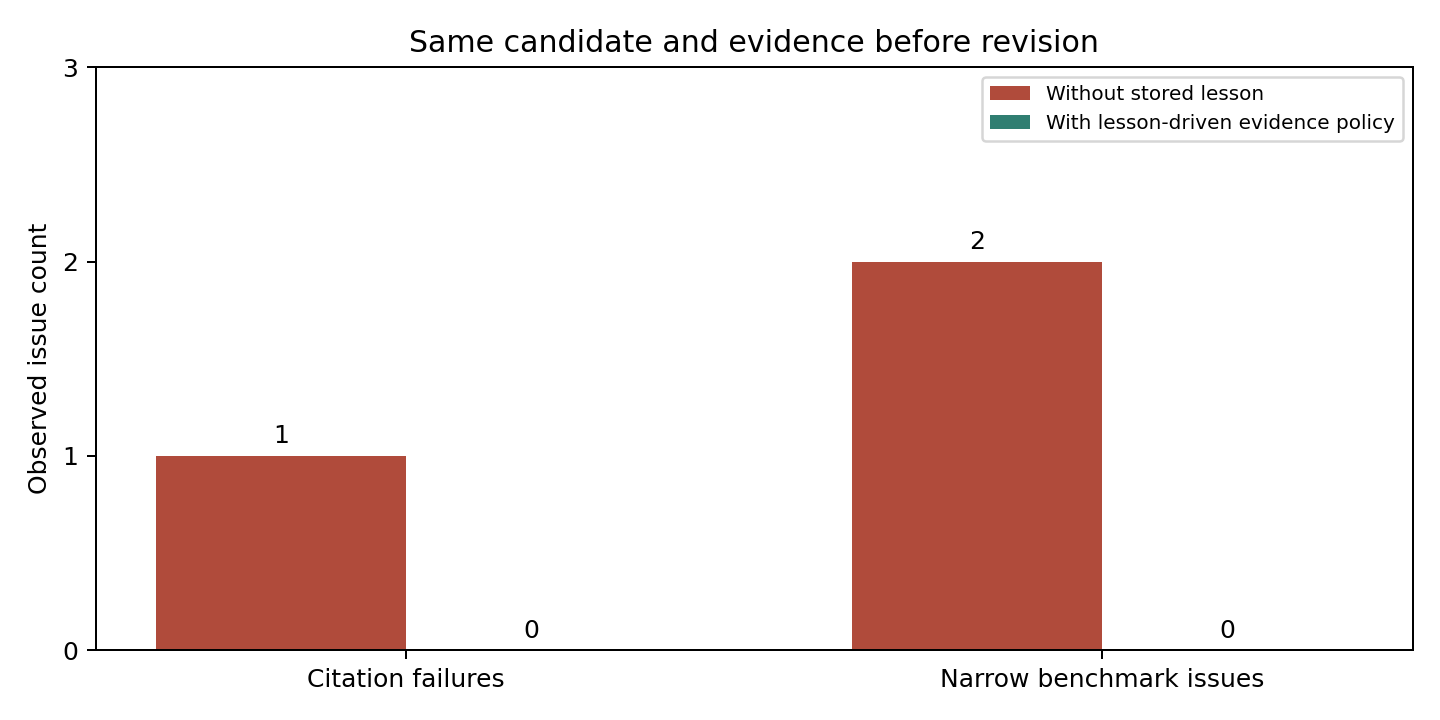

Counts describe this fixed benchmark and its narrow checks, not general accuracy.


In [18]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ablation = grounded["same_input_ablation"]
labels = ["Citation failures", "Narrow benchmark issues"]
before = [len(ablation["without_memory"]["citation_check"]["issues"]), len(ablation["without_memory"]["benchmark_check"]["issues"])]
after = [len(ablation["with_memory"]["citation_check"]["issues"]), len(ablation["with_memory"]["benchmark_check"]["issues"])]
x = list(range(len(labels)))
figure, axis = plt.subplots(figsize=(8, 4))
for offset, values, label, color in [(-0.18, before, "Without stored lesson", "#b04b3b"), (0.18, after, "With lesson-driven evidence policy", "#2f7e71")]:
    bars = axis.bar([value + offset for value in x], values, width=0.36, label=label, color=color)
    axis.bar_label(bars, padding=3)
axis.set_xticks(x, labels)
axis.set_ylabel("Observed issue count")
axis.set_title("Same candidate and evidence before revision")
axis.set_ylim(0, max(before + after) + 1)
axis.yaxis.get_major_locator().set_params(integer=True)
axis.legend(loc="upper right", fontsize=8)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "memory_policy_comparison.png", dpi=180)
from IPython.display import Image
display(Image(filename=str(OUTPUT_DIR / "memory_policy_comparison.png")))
plt.close(figure)
print("Counts describe this fixed benchmark and its narrow checks, not general accuracy.")


### What the evidence-policy demonstration establishes
The model-based reviewer, independent citation/content guards, computed evidence ledger, saved lesson and next-run policy decision are visible separately. The CPU reviewer rated even the corrected brief poorly; both legacy model-acceptance flags remain false. The positive result is independently verified correction of the supplied metrics and citations, followed by prevention of the same raw-draft errors under the saved policy. No model score or acceptance rule was changed to manufacture a pass. The corrected brief includes 20% revenue growth, 10% operating margin and 10% closing-price change with compatible periods and citations. News is quoted as supplied rather than promoted to a verified real-world event. Price change is explicitly distinguished from total return.

The evidence-tool optimizer is intentionally conservative and schema-bound. It rejects incomplete inputs instead of guessing reporting periods or financial units. A correct result on the fictional benchmark does not establish broad factual verification, predictive investment value or robustness to every real provider schema. The original AAPL example and failed Qwen baseline show why these limits matter.


In [19]:
functional_checks = {
    "Plans research": set(TEAM_PLANNER.plan("AAPL", "market financial news").specialists) == {"market", "earnings", "news"},
    "Uses selected tools": len(grounded["results"][0]["tool_trace"]) == 3 and bool(AAPL_RESULT["tool_trace"]),
    "Self-reflects": bool(grounded["results"][0]["revision_history"][0]["critical_issues"]) and len(grounded["model_calls"]) >= 3,
    "Learns across runs": grounded["checks"]["run_2_drafting_policy_activated"] and grounded["checks"]["same_input_ablation_repaired_benchmark"],
    "Prompt chaining": len(news_model_result["workflow"]) == 5 and not news_model_result["errors"],
    "Routing": TEAM_PLANNER.plan("AAPL", "earnings and revenue").specialists == ["earnings"] and TEAM_PLANNER.plan("AAPL", "recent news sentiment").specialists == ["news"],
    "Evaluator-optimizer": verification["final_evidence_checks"][0]["passed"] and grounded["results"][0]["revisions_completed"] > 0,
}
assert all(functional_checks.values()), functional_checks
print(json.dumps(functional_checks, indent=2))
print("All seven agent-function/workflow requirements have visible executable evidence.")
print("This checklist validates demonstrated behavior; it does not predict the instructor's grade.")


{
  "Plans research": true,
  "Uses selected tools": true,
  "Self-reflects": true,
  "Learns across runs": true,
  "Prompt chaining": true,
  "Routing": true,
  "Evaluator-optimizer": true
}
All seven agent-function/workflow requirements have visible executable evidence.
This checklist validates demonstrated behavior; it does not predict the instructor's grade.


## 9. Conclusions and submission record
The final project documents all four agent functions and all three workflow patterns through the source, traces, experiments and checks displayed above. The functional checklist reports what executed rather than predicting a rubric score.

The original Qwen failures remain visible. The evidence-tool experiment tests a specific architectural remedy: real model critique, a cited arithmetic brief, re-evaluation, and memory-controlled preflight drafting. The same-input comparison isolates the software-policy effect on this fixed case. It does not establish general financial reliability or a causal improvement in the underlying language model.

The final submission is this executed notebook rendered as HTML, with the GitHub branch, source records, exact runtime metadata, references and AI disclosure. The accompanying reproducibility ZIP preserves the notebook and supporting artifacts. Canvas upload is performed by the team representative; individual peer evaluations use the separate assignment link.


## References and evidence provenance
- Qwen Team. (2024). *Qwen2.5-1.5B-Instruct* [Model card]. [Hugging Face](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct). The repository's model card documents direct Transformers generation and the model context limit.
- ProsusAI. (n.d.). *FinBERT* [Model card]. [Hugging Face](https://huggingface.co/ProsusAI/finbert). Used for financial-text sentiment, not stock-return prediction.
- Aroussi, R. (n.d.). *yfinance documentation*. [Documentation](https://ranaroussi.github.io/yfinance/). Used for educational market/financial retrieval.
- Hays, T., Kaur, R., & Marx, A. (2026). *NLP_AAI520: Multi-Agent Financial Analysis System* [Source code and executed component notebooks]. [GitHub](https://github.com/tim17hays/NLP_AAI520).
- Course assignment. *AAI-520 Final Team Project Requirements*. Supplied project specification preserved in `docs/requirements/AAI-520_Final_Project_Requirements.pdf`.

The AAPL snapshot retains its original source URLs and access times. Controlled DEMO evidence is explicitly fictional. Historical controlled model results were extracted from Ashley's saved notebook stdout; no replacement scores or model responses were created during assembly.

## 10. AI assistance disclosure and responsibility
Tim used OpenAI Codex to assist with retrieval reliability, repository integration, synchronization of authored functions, evaluator/revision prompts and payloads, model-response formatting recovery, the evidence-tool optimizer, memory-policy demonstrations, regression tests, notebook assembly, narrative revision and export validation. These contributions include authorized changes to Ashley's shared evaluator/revision integration. The project documents the resulting code, design choices, tests and limitations rather than presenting unexamined AI output as verified research.

Roopleen's planning/routing/Qwen work and Ashley's evaluator/revision/memory work retain their authorship and Git history. Ashley's component notebook includes her own AI-use disclosure. Actual Colab and local model runs are identified by their recorded runtime and provenance. Tool-generated briefs, model judgments, source quotations and scripted test fixtures are distinguished throughout.

The evidence brief intentionally uses deterministic arithmetic and source-bound wording to address observed model failures; it is not claimed as an LLM-generated improvement. The team remains responsible for understanding, explaining and submitting its work. This notebook does not assert an unverified team approval or a Canvas submission.


In [ ]:
import importlib.metadata as metadata
versions = {}
for package in ("torch", "transformers", "yfinance", "requests", "nbformat", "nbconvert"):
    try: versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError: versions[package] = "not installed in this audit runtime"
manifest = {"code_commit": TEAM_COMMIT, "finished_at": datetime.now(timezone.utc).isoformat(),
            "execution_mode": "fresh_colab_models" if RUN_LIVE_MODELS else "recorded_evidence_audit",
            "versions": versions, "workflow_checks": observed["workflow_checks"],
            "quality_checks": observed["quality_checks"], "manual_findings": manual_findings,
            "grounded_checks": grounded["checks"], "independent_evidence_verification": verification, "functional_checks": functional_checks,
            "grounded_runtime": grounded["runtime"], "baseline_provenance": observed.get("provenance"),
            "report_mode": "completed_experiment_records_and_executable_verification"}
import shutil
for artifact_name in (
    "final_colab_baseline.json", "final_grounded_demonstration.json",
    "final_grounded_verification.json", "final_finbert_demonstration.json",
    "grounded_baseline_input.json",
):
    shutil.copyfile(REPO / "data/examples" / artifact_name, OUTPUT_DIR / artifact_name)
(OUTPUT_DIR / "submission_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
if IN_COLAB:
    from google.colab import _message, files
    import nbformat
    from scripts.export_submission import render_notebook
    from zipfile import ZipFile, ZIP_DEFLATED
    try:
        payload = _message.blocking_request("get_ipynb", timeout_sec=30)
        executed = nbformat.reads(json.dumps(payload["ipynb"]), as_version=4)
    except Exception as exc:
        print("Automatic notebook capture unavailable:", type(exc).__name__)
        print("Save the executed notebook with File → Download → .ipynb, then export it with scripts/export_submission.py.")
    else:
        # The current cell's output may not yet be included in Colab's snapshot.
        ipynb_path = OUTPUT_DIR / "final_multi_agent_financial_analysis.ipynb"
        nbformat.write(executed, ipynb_path)
        body = render_notebook(executed)
        ipynb_path.with_suffix(".html").write_text(body)
    archive = OUTPUT_DIR / "AAI520_final_submission_artifacts.zip"
    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        for p in OUTPUT_DIR.rglob("*"):
            if p.is_file() and p != archive:
                bundle.write(p, arcname=str(p.relative_to(OUTPUT_DIR)))
    print("Download bundle:", archive)
    files.download(str(archive))
else:
    print("Final report verification complete. Model experiment provenance is recorded above; Canvas submission is a separate action.")

{
  "code_commit": "1f9c6c42a70bb940c35f5588a68b59613485a1ff",
  "finished_at": "2026-10-20T01:51:13.171858+00:00",
  "execution_mode": "recorded_evidence_audit",
  "versions": {
    "torch": "2.11.0+cu130",
    "transformers": "5.20.1",
    "yfinance": "0.2.66",
    "requests": "2.32.4",
    "nbformat": "5.11.1",
    "nbconvert": "7.17.2"
  },
  "workflow_checks": {
    "run_1_initial_failure_detected": true,
    "run_1_revision_attempted": true,
    "run_1_changed_draft_evaluated": true,
    "run_1_process_lesson_saved": true,
    "run_1_lesson_read_from_disk": true,
    "run_2_retrieved_run_1_lesson": true,
    "run_2_plan_received_run_1_lesson": true,
    "run_2_generator_received_run_1_lesson": true,
    "all_workflow_checks_passed": true
  },
  "quality_checks": {
    "run_1_final_passed": false,
    "run_2_final_passed": false,
    "run_1_score_increased": false,
    "run_2_score_increased": false,
    "both_final_analyses_passed": false
  },
  "manual_findings": [
    {
      "